# Credit Card Fraud Detection under Extreme Class Imbalance
## Part 2: Model Comparison, Hyperparameter Tuning and Final Recommendation (Capstone 24.1)
**Author:** Asit Kar

[Part 1](fraud_detection_eda_baseline.ipynb) cleaned the data, explored it and built a logistic regression baseline. This notebook compares six classification models and four ways of handling the 1-in-600 class imbalance, tunes each model with `GridSearchCV`, and picks the model and decision threshold that give the **lowest total business cost of fraud**.

**Research question:** Can a supervised machine learning model accurately tell fraudulent transactions from legitimate ones while keeping the total business cost of missed fraud (false negatives) and blocked legitimate customers (false positives) as low as possible?

### Contents
1. Setup and data preparation
2. Evaluation framework
3. Handling class imbalance: class weights vs resampling
4. Hyperparameter tuning of six models with GridSearchCV
5. Cost-optimal decision thresholds
6. Test-set evaluation
7. Is the improvement real? Bootstrap confidence intervals
8. What drives the final model?
9. Robustness checks: cost assumptions and out-of-time validation
10. Business translation
11. Conclusions, recommendations and next steps


> **Runtime:** about 16 minutes on a 2-core machine. The data is read from `data/creditcard.csv` if it exists, otherwise from a public mirror of the Kaggle file.

## 1. Setup and data preparation

In [1]:
# Core libraries
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay, fbeta_score,
                             precision_score, recall_score)
from xgboost import XGBClassifier

# imbalanced-learn pipelines apply resampling to the training folds only
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['text.parse_math'] = False   # show $ signs literally in titles
RANDOM_STATE = 42
IMG_DIR = '../images'
os.makedirs(IMG_DIR, exist_ok=True)
notebook_start = time.time()

# One colour per model, used in every chart
BASELINE = 'Baseline LR (Part 1)'
MODEL_COLORS = {'Logistic Regression': '#4C72B0', 'k-Nearest Neighbours': '#8172B3',
                'Decision Tree': '#CCB974', 'SVM (RBF kernel)': '#64B5CD',
                'Random Forest': '#55A868', 'XGBoost': '#DD8452',
                BASELINE: '#7F7F7F', 'Dummy (always legitimate)': '#BBBBBB'}

In [2]:
# Same source logic as Part 1: use a local copy if present, otherwise the public mirror of the Kaggle file
LOCAL_PATH = '../data/creditcard.csv'
MIRROR_URL = ('https://raw.githubusercontent.com/nsethi31/'
              'Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv')
source = LOCAL_PATH if os.path.exists(LOCAL_PATH) else MIRROR_URL

# Cleaning decision from Part 1: no missing values; drop the 1,081 exact duplicate rows
transactions = pd.read_csv(source).drop_duplicates().reset_index(drop=True)


def engineer_features(df):
    # Feature engineering from Part 1, section 6
    out = df.copy()
    hour = (out['Time'] // 3600) % 24
    out['is_night'] = hour.between(0, 6).astype(int)            # fraud rate peaks overnight
    out['log_amount'] = np.log1p(out['Amount'])                  # remove the extreme right skew
    out['is_micro_amount'] = (out['Amount'] <= 1).astype(int)    # card-testing transactions
    out['hour_sin'] = np.sin(2 * np.pi * hour / 24)              # cyclical hour encoding
    out['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    return out.drop(columns=['Time', 'Amount'])


transactions_fe = engineer_features(transactions)
print(f'Transactions: {len(transactions_fe):,} | fraud: {transactions_fe["Class"].sum()} '
      f'({transactions_fe["Class"].mean():.3%}) | features: {transactions_fe.shape[1] - 1}')

Transactions: 283,726 | fraud: 473 (0.167%) | features: 33


In [3]:
X = transactions_fe.drop(columns='Class')
y = transactions_fe['Class']

# Identical stratified 80/20 split to Part 1 (same seed), so the test set is the same 56,746 transactions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

pca_cols = [f'V{i}' for i in range(1, 29)]
engineered_cols = ['is_night', 'log_amount', 'is_micro_amount', 'hour_sin', 'hour_cos']
binary_cols = ['is_night', 'is_micro_amount']

print(f'Train: {len(X_train):,} rows ({y_train.sum()} fraud) | '
      f'Test: {len(X_test):,} rows ({y_test.sum()} fraud)')

Train: 226,980 rows (378 fraud) | Test: 56,746 rows (95 fraud)


## 2. Evaluation framework

**Primary metric: PR-AUC (average precision).** Only 0.17% of transactions are fraud. Accuracy is useless (always predicting "legitimate" scores 99.83%), and ROC-AUC looks flattering because it rewards the model for the hundreds of thousands of easy true negatives. PR-AUC only asks two questions: when the model ranks transactions by risk, how high do the real frauds sit, and how clean is the alert list? A random model scores the fraud rate (0.0017) and a perfect one scores 1.0. PR-AUC is the scoring metric for every cross-validation and grid search below.

**Decision metric: expected cost.** A model outputs a score, and the bank still has to choose the cut-off above which a transaction is blocked or sent for review. The cut-off is chosen to minimise cost using the cost matrix from the Module 16 proposal:

| Outcome | Cost | Meaning |
|---|---|---|
| False negative (missed fraud) | **\$200** | average fraud loss charged back to the bank |
| False positive (false alert) | **\$5** | analyst review time and friction for a genuine customer |
| True positive / true negative | \$0 | |

**Supporting metrics:** recall (share of fraud caught), precision (share of alerts that are real fraud), and F2-score, which weights recall twice as heavily as precision. ROC-AUC is reported for completeness.

**Protocol (no test-set leakage):**
1. All tuning uses **5-fold stratified cross-validation on the training set only**.
2. Each model's cost-optimal threshold is chosen on its **out-of-fold predictions** for the training set.
3. The test set is used **once**, at the end, to compare the tuned models.

In [4]:
COST_FN, COST_FP = 200, 5   # dollars per missed fraud / per false alert
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_pipeline(clf, sampler=None, columns=None):
    # Scale continuous columns (binary flags pass through), optionally resample, then classify
    columns = list(X.columns) if columns is None else columns
    scale = [c for c in columns if c not in binary_cols]
    prep = ColumnTransformer([('scale', StandardScaler(), scale)], remainder='passthrough')
    steps = [('prep', prep)] + ([('sampler', sampler)] if sampler is not None else []) + [('clf', clf)]
    return ImbPipeline(steps)


def get_scores(model, X_part):
    # Fraud score per row: predicted probability, or the SVM decision value when there is no probability
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X_part)[:, 1]
    return model.decision_function(X_part)


def cost_by_threshold(y_true, scores, cost_fn=COST_FN, cost_fp=COST_FP):
    # Cost of every possible cut-off on the score (flag a row when score >= threshold)
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    order = np.argsort(-scores, kind='mergesort')
    s, yt = scores[order], y_true[order]
    tp, fp = np.cumsum(yt), np.cumsum(1 - yt)
    last_of_tie = np.r_[np.diff(s) != 0, True]          # tied scores are flagged together
    curve = pd.DataFrame({'threshold': s[last_of_tie], 'TP': tp[last_of_tie], 'FP': fp[last_of_tie]})
    curve = pd.concat([pd.DataFrame({'threshold': [np.inf], 'TP': [0], 'FP': [0]}), curve],
                      ignore_index=True)                 # first row = flag nothing
    curve['FN'] = yt.sum() - curve['TP']
    curve['alerts'] = curve['TP'] + curve['FP']
    curve['cost'] = curve['FN'] * cost_fn + curve['FP'] * cost_fp
    return curve


def best_threshold(y_true, scores, **costs):
    curve = cost_by_threshold(y_true, scores, **costs)
    return curve.loc[curve['cost'].idxmin(), 'threshold']


def evaluate(name, y_true, scores, threshold, cost_fn=COST_FN, cost_fp=COST_FP):
    # Metric set used throughout the project for one model at one threshold
    preds = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {'model': name, 'threshold': threshold,
            'PR_AUC': average_precision_score(y_true, scores),
            'ROC_AUC': roc_auc_score(y_true, scores),
            'recall': recall_score(y_true, preds),
            'precision': precision_score(y_true, preds, zero_division=0),
            'F2': fbeta_score(y_true, preds, beta=2, zero_division=0),
            'TP': tp, 'FP': fp, 'FN': fn, 'cost_$': fn * cost_fn + fp * cost_fp}


def format_params(params):
    return ', '.join(f"{k.split('__')[-1]}={v}" for k, v in params.items())

## 3. Handling class imbalance: class weights vs resampling

There are 378 fraud cases in the training data against about 226,600 legitimate ones. There are four common ways to stop a model from simply ignoring the minority class:

| Strategy | What it does |
|---|---|
| No adjustment | Train on the data as it is |
| Class weights | Make each fraud case count more in the loss (`class_weight='balanced'` for logistic regression, `scale_pos_weight` = 600 for XGBoost) |
| Random undersampling (1:10) | Randomly drop legitimate transactions until there are 10 for every fraud |
| SMOTE oversampling (1:10) | Create synthetic fraud cases by interpolating between real ones until there is 1 for every 10 legitimate |

Each strategy is tested on a linear model (logistic regression) and a boosted tree model (XGBoost). Resampling sits **inside** the `imblearn` pipeline, so it only touches the training folds. The validation fold always keeps its real 0.17% fraud rate, and the scores stay honest.

In [5]:
neg_pos_ratio = (y_train == 0).sum() / y_train.sum()
XGB_BASE = dict(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                tree_method='hist', eval_metric='aucpr', n_jobs=-1, random_state=RANDOM_STATE)


def imbalance_variants(model_name):
    # The four imbalance-handling variants of one model, as pipelines
    if model_name == 'Logistic Regression':
        plain = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
        weighted = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)
    else:
        plain = XGBClassifier(**XGB_BASE)
        weighted = XGBClassifier(**XGB_BASE, scale_pos_weight=neg_pos_ratio)
    return {'No adjustment': make_pipeline(plain),
            'Class weights': make_pipeline(weighted),
            'Random undersampling (1:10)': make_pipeline(
                clone(plain), RandomUnderSampler(sampling_strategy=0.1, random_state=RANDOM_STATE)),
            'SMOTE oversampling (1:10)': make_pipeline(
                clone(plain), SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE))}


fold_rows = []
for model_name in ['Logistic Regression', 'XGBoost']:
    for strategy, pipe in imbalance_variants(model_name).items():
        fold_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='average_precision',
                                      n_jobs=2 if model_name == 'Logistic Regression' else 1)
        fold_rows += [{'model': model_name, 'strategy': strategy, 'PR_AUC': s} for s in fold_scores]

imbalance_cv = pd.DataFrame(fold_rows)
imbalance_summary = (imbalance_cv.groupby(['model', 'strategy'], sort=False)['PR_AUC']
                     .agg(['mean', 'std']).unstack('model').round(3))
imbalance_summary

mean                         std  \
model                       Logistic Regression XGBoost Logistic Regression   
strategy                                                                      
No adjustment                             0.756   0.852               0.033   
Class weights                             0.756   0.850               0.028   
Random undersampling (1:10)               0.730   0.786               0.015   
SMOTE oversampling (1:10)                 0.756   0.842               0.026   

                                     
model                       XGBoost  
strategy                             
No adjustment                 0.037  
Class weights                 0.036  
Random undersampling (1:10)   0.068  
SMOTE oversampling (1:10)     0.030

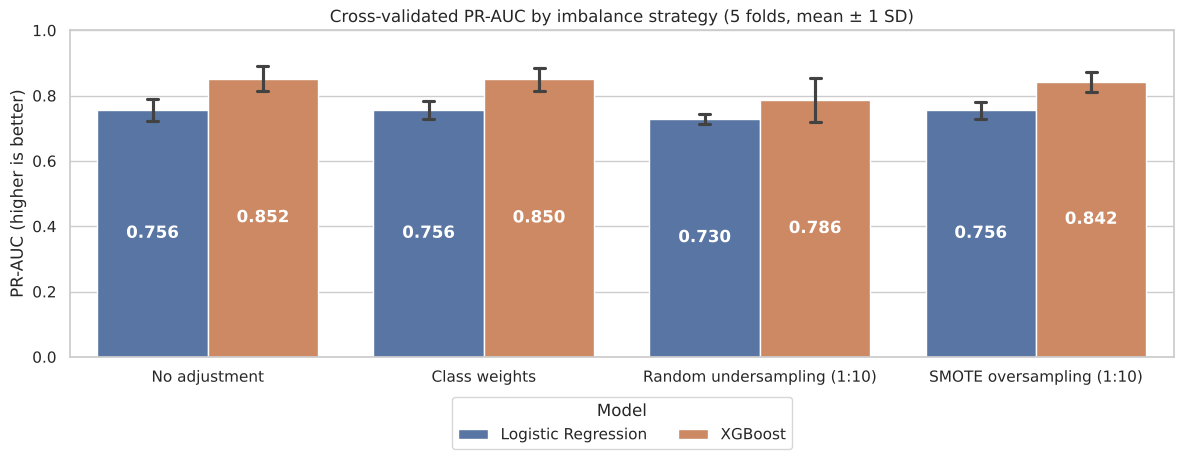

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.barplot(data=imbalance_cv, x='strategy', y='PR_AUC', hue='model', errorbar='sd', capsize=0.08,
            palette=[MODEL_COLORS['Logistic Regression'], MODEL_COLORS['XGBoost']], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', label_type='center', color='white', fontweight='bold')
ax.set_title('Cross-validated PR-AUC by imbalance strategy (5 folds, mean ± 1 SD)')
ax.set_xlabel('')
ax.set_ylabel('PR-AUC (higher is better)')
ax.set_ylim(0, 1)
ax.legend(title='Model', loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/imbalance_strategies.png', bbox_inches='tight')
plt.show()

**What this shows**
- For both models, **no adjustment, class weights and SMOTE give almost the same PR-AUC** (logistic regression 0.756 for all three; XGBoost 0.842–0.852). The differences are well inside one standard deviation across folds (≈0.03).
- **Random undersampling is the worst option** for both models (0.730 and 0.786) and the least stable one for XGBoost (SD 0.068). Throwing away 99% of the legitimate transactions removes information the model needs.
- Why don't weights or SMOTE help? PR-AUC measures how well a model *ranks* transactions. Re-weighting mostly pushes the predicted probabilities up. That moves where a 0.5 cut-off falls, but it barely changes the ranking. The cut-off is tuned for cost separately in section 5, so the simple options are enough. Class weights and resampling stay in the grid searches below as tunable settings rather than fixed choices.
- XGBoost beats logistic regression by about 0.1 PR-AUC under every strategy. **The choice of model family matters far more than the choice of imbalance technique.**

## 4. Hyperparameter tuning of six models with GridSearchCV

Every model is tuned with `GridSearchCV` (5-fold stratified CV, scored on PR-AUC) and then refit on the full training set with its best parameters.

| Model | Why it is included | Imbalance handling |
|---|---|---|
| Logistic Regression | Interpretable linear benchmark (Part 1 baseline) | `class_weight` is tuned |
| k-Nearest Neighbours | Fraud sits in the tails of the distribution, so local neighbourhoods may be informative | Undersampling ratio is tuned (also keeps distance computations tractable) |
| Decision Tree | Captures non-linear rules and is easy to explain | `class_weight` is tuned |
| SVM (RBF kernel) | Flexible non-linear boundary | Undersampling ratio is tuned (training an SVM on 227k rows is impractical) |
| Random Forest | A robust ensemble of trees | `class_weight='balanced_subsample'` is tuned |
| XGBoost | Gradient boosting, usually the strongest on tabular data | `scale_pos_weight` is tuned |

The grids are deliberately compact. Each one focuses on the parameters that matter most for that model, so the full notebook can run on a laptop.

In [7]:
search_space = {
    'Logistic Regression': (
        make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        {'clf__C': [0.01, 0.1, 1, 10], 'clf__class_weight': [None, 'balanced']}),
    'k-Nearest Neighbours': (
        make_pipeline(KNeighborsClassifier(), RandomUnderSampler(random_state=RANDOM_STATE)),
        {'sampler__sampling_strategy': [0.01, 0.1], 'clf__n_neighbors': [5, 15, 45],
         'clf__weights': ['uniform', 'distance']}),
    'Decision Tree': (
        make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        {'clf__max_depth': [4, 8, 12], 'clf__min_samples_leaf': [1, 25],
         'clf__class_weight': [None, 'balanced']}),
    'SVM (RBF kernel)': (
        make_pipeline(SVC(kernel='rbf'), RandomUnderSampler(random_state=RANDOM_STATE)),
        {'sampler__sampling_strategy': [0.05, 0.2], 'clf__C': [0.1, 1, 10], 'clf__gamma': ['scale', 0.01]}),
    'Random Forest': (
        make_pipeline(RandomForestClassifier(n_estimators=100, max_samples=0.5, min_samples_leaf=3,
                                             n_jobs=-1, random_state=RANDOM_STATE)),
        {'clf__max_depth': [12, None], 'clf__class_weight': [None, 'balanced_subsample']}),
    'XGBoost': (
        make_pipeline(XGBClassifier(**{k: v for k, v in XGB_BASE.items()
                                       if k not in ('max_depth', 'learning_rate')})),
        {'clf__max_depth': [3, 5], 'clf__learning_rate': [0.05, 0.1], 'clf__scale_pos_weight': [1, 10]}),
}

searches, tuning_rows = {}, []
for name, (pipe, grid) in search_space.items():
    start = time.time()
    # tree ensembles already use every core internally, so their grid search runs folds one at a time
    n_jobs = 1 if name in ('Random Forest', 'XGBoost') else 2
    search = GridSearchCV(pipe, grid, scoring='average_precision', cv=cv, n_jobs=n_jobs, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    tuning_rows.append({'model': name,
                        'grid_size': len(search.cv_results_['params']),
                        'CV_PR_AUC': search.best_score_,
                        'CV_std': search.cv_results_['std_test_score'][search.best_index_],
                        'best_params': format_params(search.best_params_),
                        'minutes': (time.time() - start) / 60})

tuning_summary = pd.DataFrame(tuning_rows).set_index('model').sort_values('CV_PR_AUC', ascending=False)
tuning_summary.style.format({'CV_PR_AUC': '{:.3f}', 'CV_std': '{:.3f}', 'minutes': '{:.1f}'})

,grid_size,CV_PR_AUC,CV_std,best_params,minutes
model,,,,,
XGBoost,8,0.853,0.029,"learning_rate=0.1, max_depth=5, scale_pos_weight=10",1.7
Random Forest,4,0.836,0.035,"class_weight=balanced_subsample, max_depth=None",5.9
k-Nearest Neighbours,12,0.792,0.042,"n_neighbors=45, weights=distance, sampling_strategy=0.01",1.3
Decision Tree,12,0.767,0.038,"class_weight=None, max_depth=4, min_samples_leaf=25",2.1
Logistic Regression,8,0.757,0.024,"C=0.01, class_weight=balanced",0.1
SVM (RBF kernel),12,0.745,0.029,"C=10, gamma=0.01, sampling_strategy=0.05",0.4


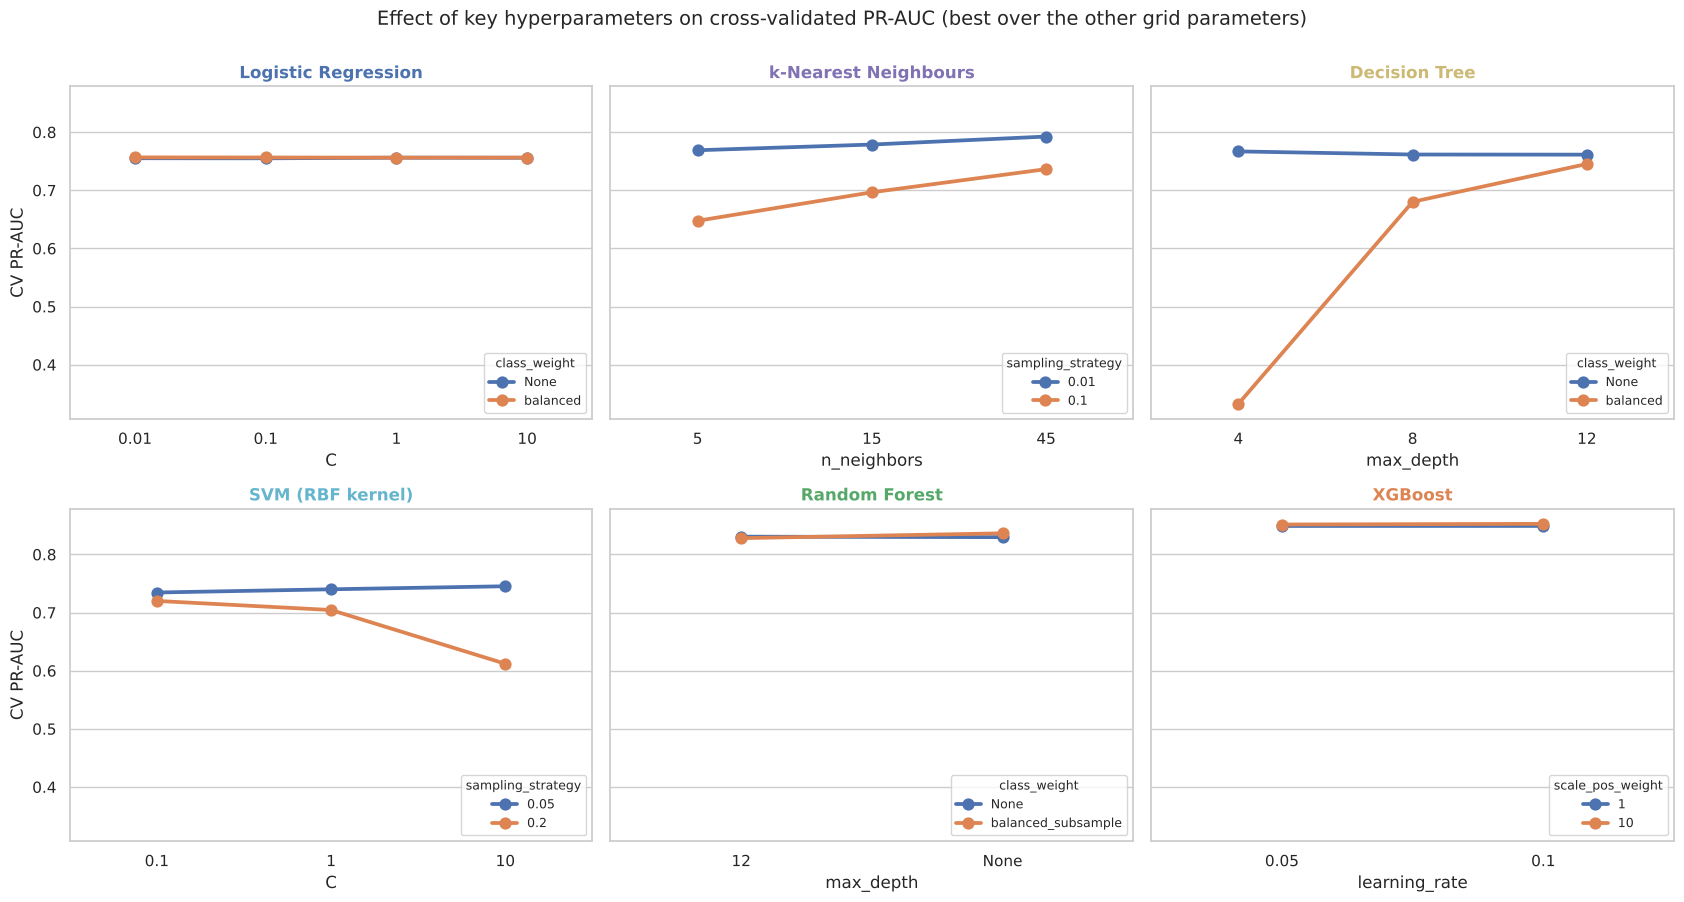

In [8]:
def grid_effect(search, x, hue):
    # Best CV PR-AUC for each (x, hue) pair, taking the best over all other parameters
    params = search.cv_results_['params']
    # string labels so that None (e.g. no class weights, unlimited depth) shows up as its own category
    res = pd.DataFrame({key.split('__')[-1]: [str(p[key]) for p in params] for key in params[0]})
    res['PR_AUC'] = search.cv_results_['mean_test_score']
    return res.groupby([x, hue], as_index=False, sort=False)['PR_AUC'].max()


effect_specs = [('Logistic Regression', 'C', 'class_weight'),
                ('k-Nearest Neighbours', 'n_neighbors', 'sampling_strategy'),
                ('Decision Tree', 'max_depth', 'class_weight'),
                ('SVM (RBF kernel)', 'C', 'sampling_strategy'),
                ('Random Forest', 'max_depth', 'class_weight'),
                ('XGBoost', 'learning_rate', 'scale_pos_weight')]

fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharey=True)
for ax, (name, x, hue) in zip(axes.flat, effect_specs):
    sns.pointplot(data=grid_effect(searches[name], x, hue), x=x, y='PR_AUC', hue=hue,
                  palette='deep', markers='o', ax=ax)
    ax.set_title(name, color=MODEL_COLORS[name], fontweight='bold')
    ax.set_xlabel(x)
    ax.set_ylabel('CV PR-AUC')
    ax.legend(title=hue, fontsize=9, title_fontsize=9, loc='lower right')
fig.suptitle('Effect of key hyperparameters on cross-validated PR-AUC (best over the other grid parameters)',
             fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/hyperparameter_effects.png', bbox_inches='tight')
plt.show()

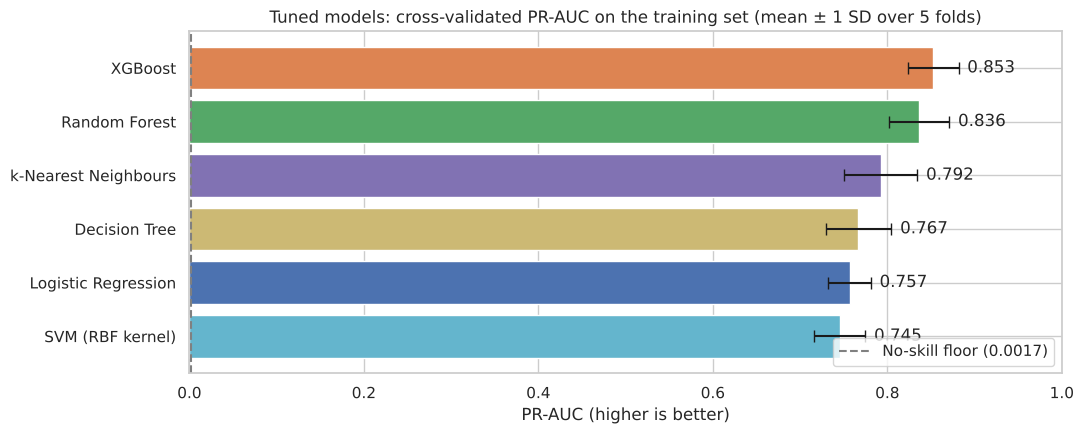

In [9]:
plot_df = tuning_summary.reset_index().sort_values('CV_PR_AUC')
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(plot_df['model'], plot_df['CV_PR_AUC'], xerr=plot_df['CV_std'], capsize=4,
        color=[MODEL_COLORS[m] for m in plot_df['model']])
for i, (score, sd) in enumerate(zip(plot_df['CV_PR_AUC'], plot_df['CV_std'])):
    ax.text(score + sd + 0.01, i, f'{score:.3f}', va='center')
ax.axvline(y_train.mean(), ls='--', color='grey', label=f'No-skill floor ({y_train.mean():.4f})')
ax.set_title('Tuned models: cross-validated PR-AUC on the training set (mean ± 1 SD over 5 folds)')
ax.set_xlabel('PR-AUC (higher is better)')
ax.set_xlim(0, 1)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/cv_pr_auc_by_model.png', bbox_inches='tight')
plt.show()

**Interpreting the tuned models**
- **XGBoost has the highest cross-validated PR-AUC (0.853 ± 0.029)**, followed by Random Forest (0.836). The two tree ensembles clearly beat the other four models (0.745–0.792). Fraud shows up as non-linear combinations of several components (for example, a very low V14 together with a high V4), and ensembles of trees capture those combinations best.
- **Logistic regression** barely responds to the regularisation strength `C`. Its best setting (C = 0.01, balanced weights) scores 0.757, the same as the Part 1 baseline, so the linear model has reached its ceiling.
- **k-NN** improves with more neighbours (45) and with keeping more of the legitimate transactions (1:100 undersampling rather than 1:10). It does well for such a simple method, but scoring each new transaction against a stored reference set is slow in production.
- **Decision tree:** without class weights, depth barely matters (0.76–0.77) and the simplest tree (depth 4, at least 25 rows per leaf) is best. With balanced weights the tree needs depth 12 to recover, and it scores only 0.33 at depth 4.
- **SVM:** keeping more legitimate data (1:20 rather than 1:5) works best. With the 1:5 sample, a high `C` overfits (0.61 at C = 10). It is the weakest of the six models and could only be trained on a small sample.
- **XGBoost** scores between 0.849 and 0.853 across its whole grid. The model family matters much more than the exact setting, which suggests the result is robust and not the product of a lucky configuration.
- Each validation fold holds only about 76 frauds, so the fold-to-fold SD (0.02–0.04) is large compared with some of the gaps. Differences smaller than about 0.03 between models should not be over-interpreted.

## 5. Cost-optimal decision thresholds

A classifier's default cut-off (probability ≥ 0.5) assumes that both kinds of mistake cost the same. Here a missed fraud costs **40 times** as much as a false alert, so the right cut-off is usually much lower. For each tuned model:

1. `cross_val_predict` produces an **out-of-fold score** for every training transaction, which means each score comes from a model that did not see that row.
2. `cost_by_threshold` evaluates the total cost of every possible cut-off on those scores, and the cheapest one is kept.

The search works on any score scale, so it also handles the SVM, which outputs a decision value rather than a probability. The same steps are applied to the Part 1 baseline (default logistic regression), which keeps the comparison fair.

In [10]:
# Final model = highest cross-validated PR-AUC (the primary metric), chosen before the test set is touched
final_name = tuning_summary.index[0]
final_models = {name: search.best_estimator_ for name, search in searches.items()}
final_models[BASELINE] = make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)).fit(X_train, y_train)

oof_scores, thresholds, oof_rows = {}, {}, []
for name, model in final_models.items():
    method = 'predict_proba' if hasattr(model, 'predict_proba') else 'decision_function'
    n_jobs = 1 if name in ('Random Forest', 'XGBoost') else 2
    oof = cross_val_predict(clone(model), X_train, y_train, cv=cv, method=method, n_jobs=n_jobs)
    oof_scores[name] = oof[:, 1] if oof.ndim == 2 else oof
    thresholds[name] = best_threshold(y_train, oof_scores[name])
    oof_rows.append(evaluate(name, y_train, oof_scores[name], thresholds[name]))

oof_summary = pd.DataFrame(oof_rows).set_index('model').sort_values('cost_$')
oof_summary[['threshold', 'PR_AUC', 'recall', 'precision', 'F2', 'TP', 'FP', 'FN', 'cost_$']].style.format(
    {'threshold': '{:.3f}', 'PR_AUC': '{:.3f}', 'recall': '{:.1%}', 'precision': '{:.1%}',
     'F2': '{:.3f}', 'cost_$': '${:,.0f}'})

,threshold,PR_AUC,recall,precision,F2,TP,FP,FN,cost_$
model,,,,,,,,,
Random Forest,0.050,0.837,87.0%,50.1%,0.758,329,328,49,"$11,440"
XGBoost,0.009,0.852,85.4%,61.3%,0.792,323,204,55,"$12,020"
Logistic Regression,0.975,0.737,85.7%,56.2%,0.775,324,253,54,"$12,065"
k-Nearest Neighbours,0.066,0.789,86.5%,44.3%,0.727,327,411,51,"$12,255"
Baseline LR (Part 1),0.012,0.754,86.5%,43.5%,0.722,327,424,51,"$12,320"
Decision Tree,0.035,0.764,84.4%,65.9%,0.799,319,165,59,"$12,625"
SVM (RBF kernel),-0.015,0.737,83.9%,58.1%,0.770,317,229,61,"$13,345"


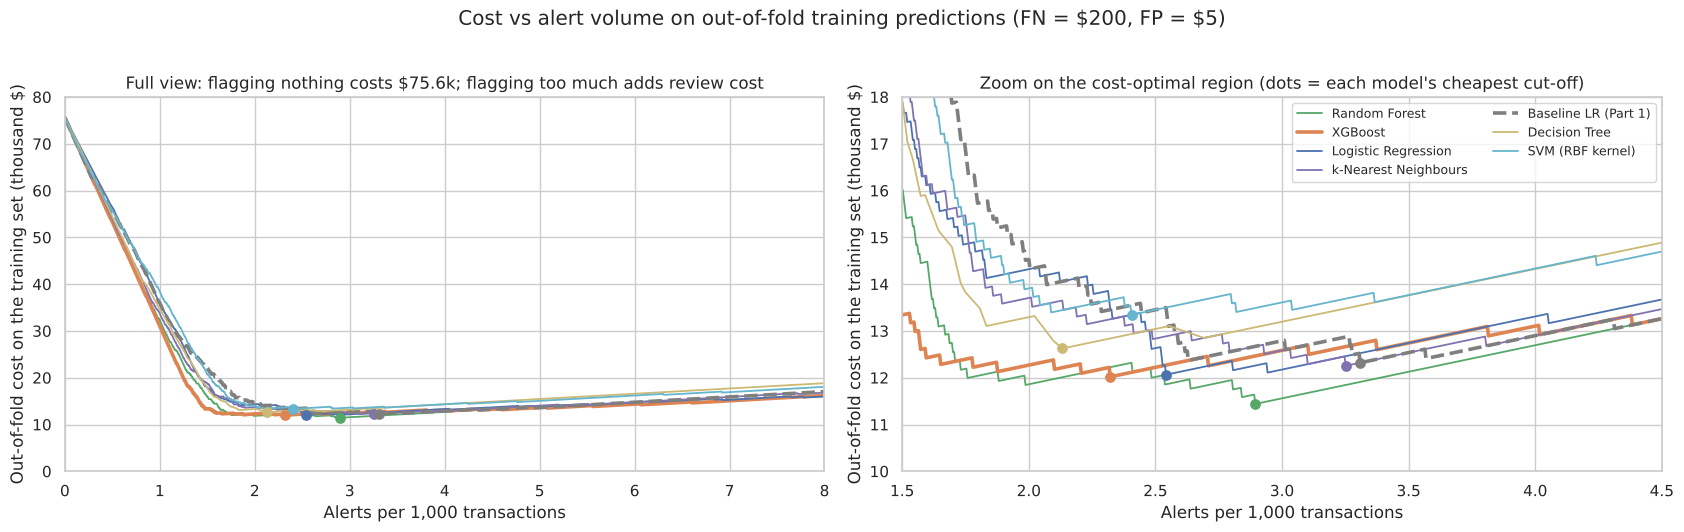

In [11]:
# Cost against alert volume: a scale-free view that puts probability and SVM scores on one axis
fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
for name in oof_summary.index:
    curve = cost_by_threshold(y_train, oof_scores[name])
    alerts_per_1000 = curve['alerts'] / len(y_train) * 1000
    best = curve['cost'].idxmin()
    for ax in axes:
        ax.plot(alerts_per_1000, curve['cost'] / 1000, color=MODEL_COLORS[name],
                lw=2.6 if name in (final_name, BASELINE) else 1.3,
                ls='--' if name == BASELINE else '-', label=name)
        ax.scatter(alerts_per_1000[best], curve['cost'][best] / 1000, color=MODEL_COLORS[name], s=45, zorder=3)
axes[0].set_xlim(0, 8)
axes[0].set_ylim(0, 80)
axes[0].set_title('Full view: flagging nothing costs $75.6k; flagging too much adds review cost')
axes[1].set_xlim(1.5, 4.5)
axes[1].set_ylim(10, 18)
axes[1].set_title('Zoom on the cost-optimal region (dots = each model\'s cheapest cut-off)')
for ax in axes:
    ax.set_xlabel('Alerts per 1,000 transactions')
    ax.set_ylabel('Out-of-fold cost on the training set (thousand $)')
axes[1].legend(ncol=2, fontsize=9, loc='upper right')
fig.suptitle(f'Cost vs alert volume on out-of-fold training predictions (FN = ${COST_FN}, FP = ${COST_FP})', y=1.02)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/cost_vs_alert_volume.png', bbox_inches='tight')
plt.show()

**What the cost curves show**
- Every model's cost-optimal cut-off flags only **2 to 3.5 transactions per 1,000**. Flagging nothing costs \$75,600 on the training data. Each extra false alert adds only \$5, so the curve falls steeply on the left and rises slowly on the right. **It is cheaper to raise a few too many alerts than too few.**
- The optimal probability cut-offs sit far below 0.5: 0.009 for XGBoost and 0.012 for the baseline. The exception is the balanced logistic regression (0.975), because its class weights push every probability up. A threshold therefore has to be tuned for each model; no rule of thumb works.
- On the out-of-fold training predictions, Random Forest (\$11,440) and XGBoost (\$12,020) are cheapest, about \$300–\$900 below the baseline (\$12,320). Gaps this small amount to a handful of frauds, so the test set (section 6) and the bootstrap (section 7) are needed to judge them.

## 6. Test-set evaluation

The **final model was fixed before the test set was touched**: it is the model with the highest cross-validated PR-AUC, the primary metric (section 4), used at its cost-optimal threshold from section 5. The test set (56,746 transactions, 95 frauds, never used for tuning) then gives an unbiased check of every model at its own cost-optimal threshold.

In [12]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

test_scores = {name: get_scores(model, X_test) for name, model in final_models.items()}
test_rows = [evaluate('Dummy (always legitimate)', y_test, dummy.predict_proba(X_test)[:, 1], 0.5)]
for name in final_models:
    row = evaluate(name, y_test, test_scores[name], thresholds[name])
    row['CV_PR_AUC'] = tuning_summary['CV_PR_AUC'].get(name, np.nan)
    # cost if the default 0.5 cut-off were used instead (probability models only)
    row['cost_at_0.5_$'] = (evaluate(name, y_test, test_scores[name], 0.5)['cost_$']
                            if hasattr(final_models[name], 'predict_proba') else np.nan)
    test_rows.append(row)

test_results = pd.DataFrame(test_rows).set_index('model').sort_values('cost_$')
test_results['saving_vs_baseline_$'] = test_results.loc[BASELINE, 'cost_$'] - test_results['cost_$']
print(f'Final model (highest cross-validated PR-AUC): {final_name}')

cols = ['CV_PR_AUC', 'PR_AUC', 'ROC_AUC', 'recall', 'precision', 'F2', 'TP', 'FP', 'FN',
        'cost_at_0.5_$', 'cost_$', 'saving_vs_baseline_$']
test_results[cols].style.format(
    {'CV_PR_AUC': '{:.3f}', 'PR_AUC': '{:.3f}', 'ROC_AUC': '{:.3f}', 'recall': '{:.1%}',
     'precision': '{:.1%}', 'F2': '{:.3f}', 'cost_at_0.5_$': '${:,.0f}', 'cost_$': '${:,.0f}',
     'saving_vs_baseline_$': '${:,.0f}'}, na_rep='–').highlight_min(subset=['cost_$'], color='#d5f0d5')

Final model (highest cross-validated PR-AUC): XGBoost


,CV_PR_AUC,PR_AUC,ROC_AUC,recall,precision,F2,TP,FP,FN,cost_at_0.5_$,cost_$,saving_vs_baseline_$
model,,,,,,,,,,,,
XGBoost,0.853,0.820,0.976,84.2%,65.0%,0.795,80,43,15,"$4,610","$3,215","$1,270"
Random Forest,0.836,0.805,0.938,81.1%,52.0%,0.729,77,71,18,"$5,225","$3,955",$530
SVM (RBF kernel),0.745,0.733,0.970,78.9%,65.8%,0.759,75,39,20,–,"$4,195",$290
Logistic Regression,0.757,0.671,0.966,78.9%,60.0%,0.743,75,50,20,"$9,270","$4,250",$235
Baseline LR (Part 1),–,0.695,0.953,78.9%,43.6%,0.679,75,97,20,"$7,645","$4,485",$0
k-Nearest Neighbours,0.792,0.769,0.923,78.9%,41.9%,0.671,75,104,20,"$5,255","$4,520",$-35
Decision Tree,0.767,0.665,0.879,74.7%,65.1%,0.726,71,38,24,"$5,885","$4,990",$-505
Dummy (always legitimate),–,0.002,0.500,0.0%,0.0%,0.000,0,0,95,–,"$19,000","$-14,515"


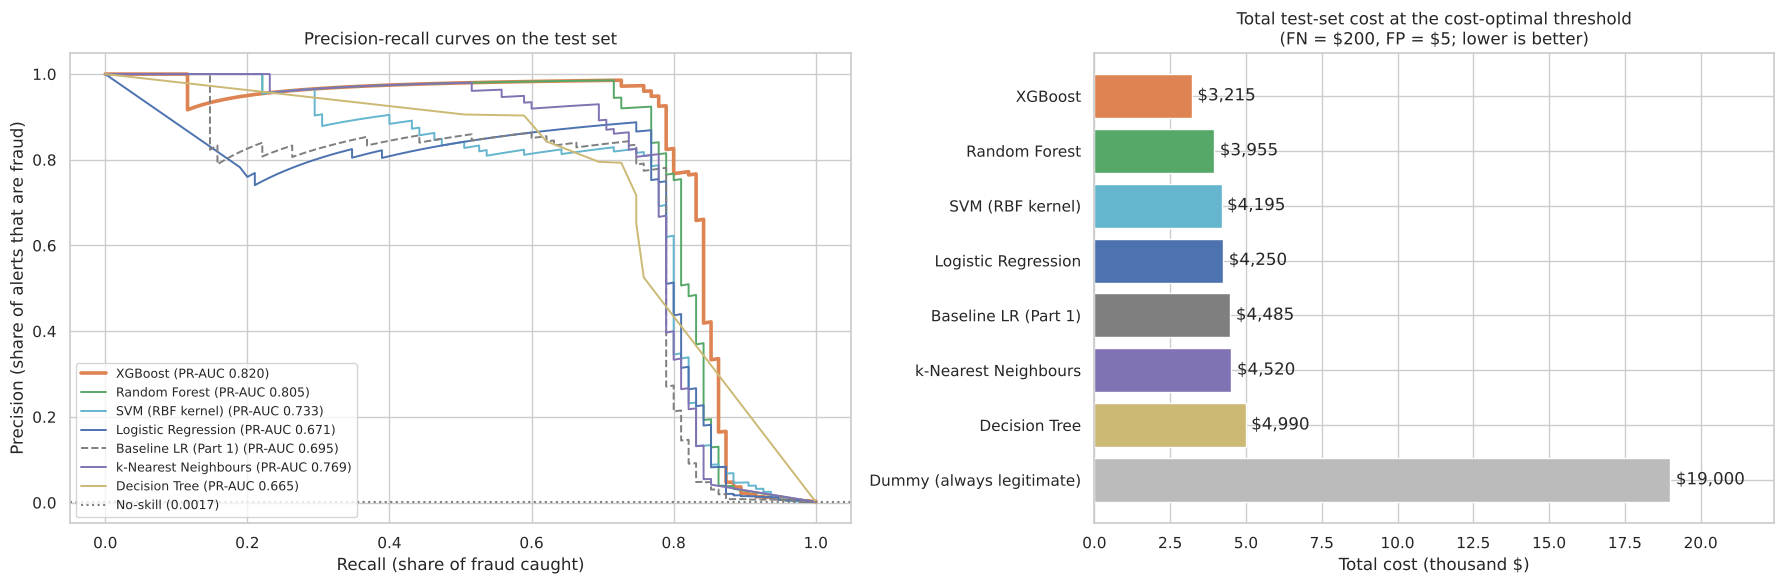

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1.15, 1]})

# Left: precision-recall curves on the test set
for name in test_results.index.drop('Dummy (always legitimate)'):
    precision, recall, _ = precision_recall_curve(y_test, test_scores[name])
    axes[0].plot(recall, precision, color=MODEL_COLORS[name], ls='--' if name == BASELINE else '-',
                 lw=2.6 if name == final_name else 1.4,
                 label=f"{name} (PR-AUC {test_results.loc[name, 'PR_AUC']:.3f})")
axes[0].axhline(y_test.mean(), ls=':', color='grey', label=f'No-skill ({y_test.mean():.4f})')
axes[0].set_title('Precision-recall curves on the test set')
axes[0].set_xlabel('Recall (share of fraud caught)')
axes[0].set_ylabel('Precision (share of alerts that are fraud)')
axes[0].legend(fontsize=9, loc='lower left')

# Right: total test cost at each model's cost-optimal threshold
cost_df = test_results['cost_$'].sort_values(ascending=False)
bars = axes[1].barh(cost_df.index, cost_df.values / 1000, color=[MODEL_COLORS[m] for m in cost_df.index])
axes[1].bar_label(bars, labels=[f'${v:,.0f}' for v in cost_df.values], padding=4)
axes[1].set_title(f'Total test-set cost at the cost-optimal threshold\n(FN = ${COST_FN}, FP = ${COST_FP}; lower is better)')
axes[1].set_xlabel('Total cost (thousand $)')
axes[1].set_xlim(0, cost_df.max() / 1000 * 1.18)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/test_pr_curves_and_cost.png', bbox_inches='tight')
plt.show()

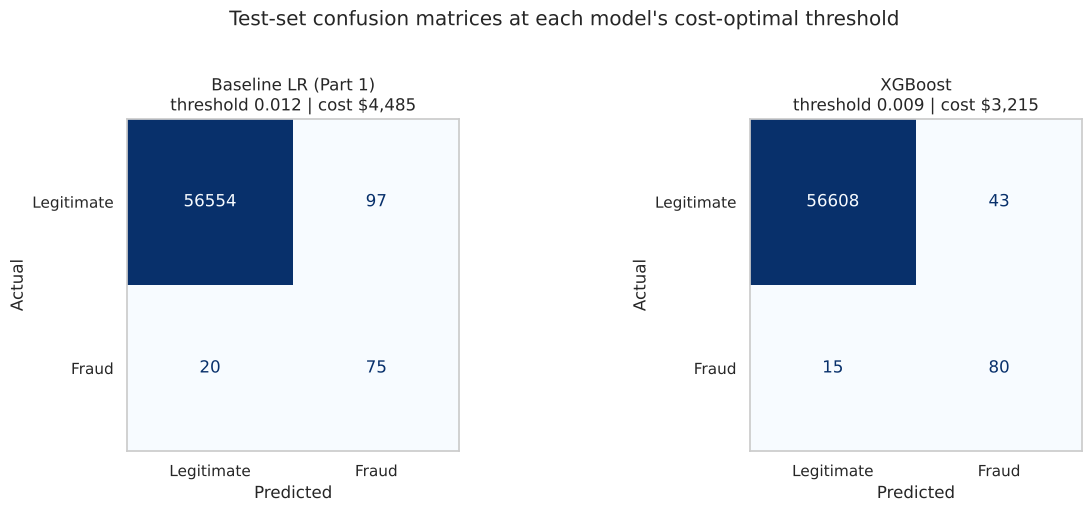

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, [BASELINE, final_name]):
    preds = (test_scores[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=['Legitimate', 'Fraud'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f"{name}\nthreshold {thresholds[name]:.3f} | cost ${test_results.loc[name, 'cost_$']:,.0f}")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.grid(False)
plt.suptitle('Test-set confusion matrices at each model\'s cost-optimal threshold', y=1.02)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/confusion_matrices_final.png', bbox_inches='tight')
plt.show()

**Results on the unseen test set**
- **XGBoost is the best model on every headline metric.** It has the highest PR-AUC (0.820 vs 0.695 for the baseline) and the highest F2 (0.795). Its **cost is the lowest: \$3,215 vs \$4,485 for the baseline, a saving of \$1,270 (28%)**. It catches **80 of the 95 frauds (84%)**, and **65% of its alerts are real fraud**, against 44% for the baseline.
- The test ranking matches the cross-validation ranking: the two tree ensembles come first and the decision tree comes last. That suggests the CV estimates were reliable.
- **Tuning the threshold is worth as much as choosing the model.** At the default 0.5 cut-off XGBoost would cost \$4,610 because it misses more fraud. At its cost-optimal cut-off the cost is \$3,215. The balanced logistic regression would cost \$9,270 at 0.5, because it floods analysts with false alerts.
- The confusion matrices show where the saving comes from. Compared with the baseline, XGBoost catches **5 more frauds** (\$1,000 saved) and raises **54 fewer false alerts** (\$270 saved).
- The baseline's test cost here (\$4,485) is slightly higher than in Part 1 (\$4,265). Its threshold is now chosen from out-of-fold predictions on the whole training set, like every other model, rather than from a single validation split.
- ROC-AUC is above 0.92 for every model except the decision tree, and it barely separates them (0.953 for the baseline vs 0.976 for XGBoost). This is why ROC-AUC was not used as the primary metric.

## 7. Is the improvement real? Bootstrap confidence intervals

The test set holds only 95 frauds, so a gap of a few frauds between two models could be luck. A **paired bootstrap** checks this. It draws 2,000 resamples of the test set with replacement, scores both models on the same resample each time, and records the cost saving and the PR-AUC gain of the final model over the baseline. The middle 95% of those values is the confidence interval.

In [15]:
def row_costs(y_true, preds):
    # Cost contributed by each transaction: $200 per missed fraud, $5 per false alert
    return np.where((preds == 0) & (y_true == 1), COST_FN, np.where((preds == 1) & (y_true == 0), COST_FP, 0))


y_test_arr = y_test.to_numpy()
final_cost_rows = row_costs(y_test_arr, (test_scores[final_name] >= thresholds[final_name]).astype(int))
base_cost_rows = row_costs(y_test_arr, (test_scores[BASELINE] >= thresholds[BASELINE]).astype(int))

rng = np.random.default_rng(RANDOM_STATE)
boot_rows = []
for _ in range(2000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    boot_rows.append({
        'cost_saving_$': base_cost_rows[idx].sum() - final_cost_rows[idx].sum(),
        'PR_AUC_gain': (average_precision_score(y_test_arr[idx], test_scores[final_name][idx])
                        - average_precision_score(y_test_arr[idx], test_scores[BASELINE][idx]))})
bootstrap = pd.DataFrame(boot_rows)

bootstrap_summary = pd.DataFrame({
    'observed': [base_cost_rows.sum() - final_cost_rows.sum(),
                 test_results.loc[final_name, 'PR_AUC'] - test_results.loc[BASELINE, 'PR_AUC']],
    'CI_2.5%': bootstrap.quantile(0.025).values,
    'CI_97.5%': bootstrap.quantile(0.975).values,
    'share_of_resamples_>_0': (bootstrap > 0).mean().values}, index=bootstrap.columns)
bootstrap_summary.round(3)

,observed,CI_2.5%,CI_97.5%,share_of_resamples_>_0
cost_saving_$,1270.000,489.875,2290.000,1.0
PR_AUC_gain,0.126,0.056,0.203,1.0


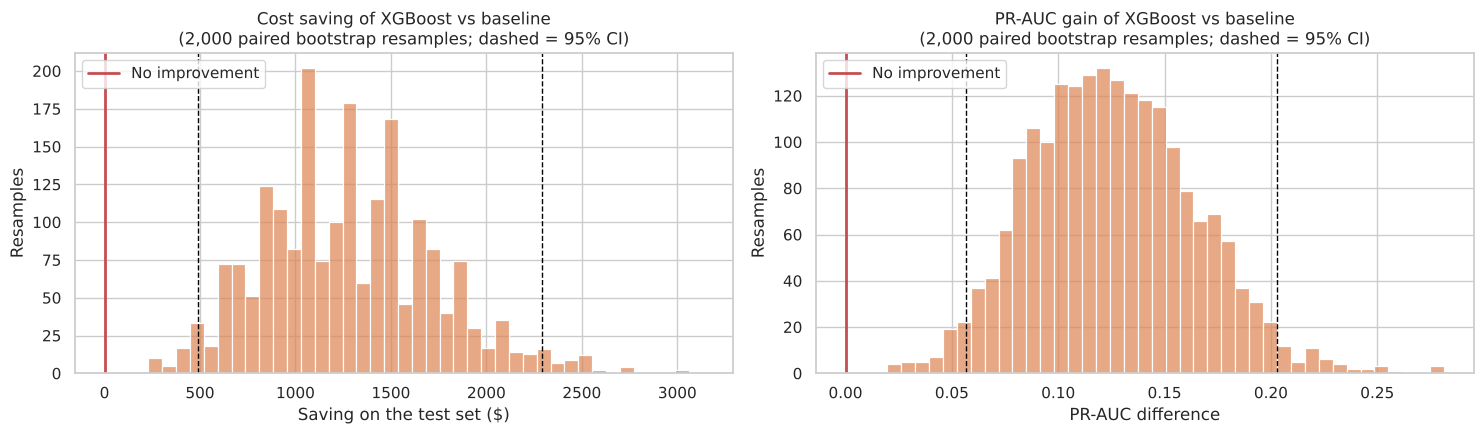

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col, title, xlabel in [
        (axes[0], 'cost_saving_$', f'Cost saving of {final_name} vs baseline', 'Saving on the test set ($)'),
        (axes[1], 'PR_AUC_gain', f'PR-AUC gain of {final_name} vs baseline', 'PR-AUC difference')]:
    sns.histplot(bootstrap[col], bins=40, color=MODEL_COLORS[final_name], alpha=0.7, ax=ax)
    for q in bootstrap[col].quantile([0.025, 0.975]):
        ax.axvline(q, color='black', ls='--', lw=1)
    ax.axvline(0, color='#C44E52', lw=2, label='No improvement')
    ax.set_title(f'{title}\n(2,000 paired bootstrap resamples; dashed = 95% CI)')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Resamples')
    ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/bootstrap_improvement.png', bbox_inches='tight')
plt.show()

**Is the improvement real?**
- The **cost saving of XGBoost over the baseline is \$1,270, with a 95% confidence interval of about \$490 to \$2,290**. XGBoost was cheaper in virtually every one of the 2,000 resamples.
- The **PR-AUC gain is 0.126 (95% CI 0.056 to 0.203)**. This interval also excludes zero.
- The improvement is therefore very unlikely to be a fluke of this particular test sample. The intervals are wide, though, because the test set holds only 95 frauds. The exact size of the saving is uncertain: somewhere between about 10% and 50% of the baseline's cost.

## 8. What drives the final model?

**Permutation importance** shuffles one feature at a time on the test set and measures how much PR-AUC drops. A large drop means the model relies on that feature. The model's own split-based importance is shown alongside for comparison.

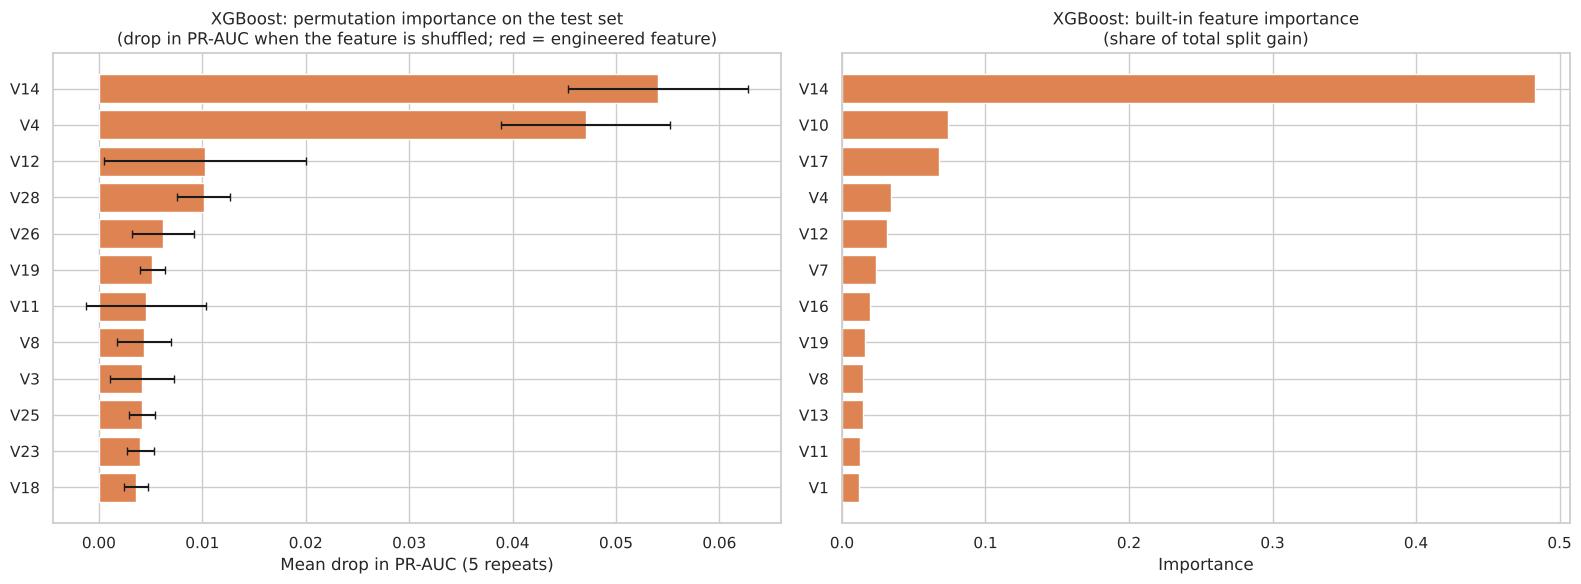

,V14,V4,V12,V28,V26,V19,V11,V8
mean,0.0541,0.0471,0.0103,0.0101,0.0062,0.0052,0.0046,0.0043
std,0.0087,0.0082,0.0098,0.0025,0.0030,0.0012,0.0058,0.0026


In [17]:
final_model = final_models[final_name]
perm = permutation_importance(final_model, X_test, y_test, scoring='average_precision',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
perm_importance = (pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std}, index=X_test.columns)
                   .sort_values('mean', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top_perm = perm_importance.head(12).iloc[::-1]
axes[0].barh(top_perm.index, top_perm['mean'], xerr=top_perm['std'], capsize=3,
             color=['#C44E52' if c in engineered_cols else MODEL_COLORS[final_name] for c in top_perm.index])
axes[0].set_title(f'{final_name}: permutation importance on the test set\n(drop in PR-AUC when the feature is shuffled; red = engineered feature)')
axes[0].set_xlabel('Mean drop in PR-AUC (5 repeats)')

clf = final_model.named_steps['clf']
if hasattr(clf, 'feature_importances_'):
    feature_names = [n.split('__')[-1] for n in final_model.named_steps['prep'].get_feature_names_out()]
    builtin = pd.Series(clf.feature_importances_, index=feature_names).sort_values().tail(12)
    axes[1].barh(builtin.index, builtin.values,
                 color=['#C44E52' if c in engineered_cols else MODEL_COLORS[final_name] for c in builtin.index])
    axes[1].set_title(f'{final_name}: built-in feature importance\n(share of total split gain)')
    axes[1].set_xlabel('Importance')
else:
    axes[1].axis('off')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/feature_importance.png', bbox_inches='tight')
plt.show()
perm_importance.head(8).round(4).T

**Do the engineered features from Part 1 add value?** The final model is cross-validated with and without the five engineered time and amount features.

In [18]:
best_steps = final_model.named_steps
ablation = {}
for label, cols in [('V1-V28 only', pca_cols), ('V1-V28 + engineered features', pca_cols + engineered_cols)]:
    pipe = make_pipeline(clone(best_steps['clf']),
                         clone(best_steps['sampler']) if 'sampler' in best_steps else None, columns=cols)
    fold_scores = cross_val_score(pipe, X_train[cols], y_train, cv=cv, scoring='average_precision', n_jobs=1)
    ablation[label] = {'CV_PR_AUC': fold_scores.mean(), 'CV_std': fold_scores.std()}
pd.DataFrame(ablation).T.round(4)

,CV_PR_AUC,CV_std
V1-V28 only,0.8434,0.0266
V1-V28 + engineered features,0.8527,0.0289


**What the model relies on**
- **V14 and V4 dominate.** Shuffling either one cuts the test PR-AUC by about 0.05, and no other feature costs more than about 0.01. XGBoost's built-in importance also puts V14 far ahead, followed by V10, V17, V4 and V12. All five were in the top six by KS statistic in the Part 1 EDA, where V14 ranked first (0.84).
- The model depends on a handful of anonymised components. They are PCA outputs whose original meaning is confidential, so the model can show *which* signals drove a decision but not *what* they mean in business terms. That limits customer-facing explanations (see next steps).
- **Engineered features:** adding the five time and amount features raises the CV PR-AUC from 0.843 to 0.853. The gain is smaller than the fold-to-fold SD (≈0.03), so at best they help slightly. They are kept because they cost nothing and are meaningful to fraud analysts (night-time and micro-transaction flags).

## 9. Robustness checks
### 9.1 What if the cost assumptions are wrong?
The \$200 / \$5 cost matrix is an estimate. A bank with larger average fraud losses, or cheaper reviews, would choose a different cut-off. Here the missed-fraud cost varies from \$50 to \$1,000 (the false-alert cost stays at \$5). The threshold is re-optimised on the training data for each value and then checked on the test set.

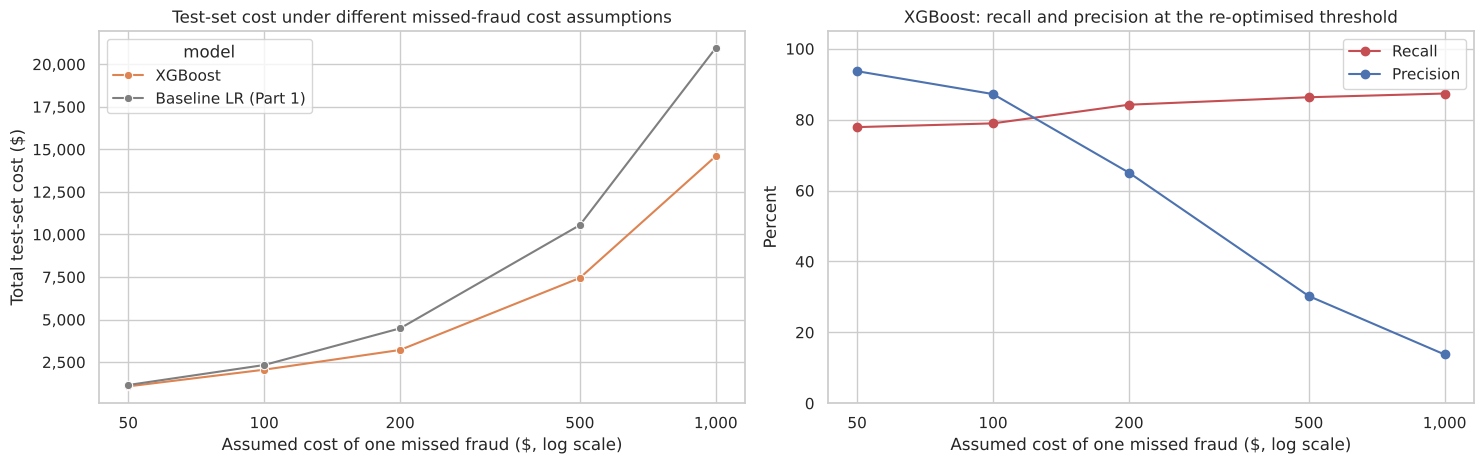

cost_$                    recall_pct  \
model               Baseline LR (Part 1)  XGBoost Baseline LR (Part 1)   
missed_fraud_cost_$                                                      
50                                1155.0   1075.0                 78.9   
100                               2330.0   2055.0                 78.9   
200                               4485.0   3215.0                 78.9   
500                              10550.0   7445.0                 78.9   
1000                             20960.0  14600.0                 78.9   

                                          alerts          
model               XGBoost Baseline LR (Part 1) XGBoost  
missed_fraud_cost_$                                       
50                     77.9                106.0    79.0  
100                    78.9                141.0    86.0  
200                    84.2                172.0   123.0  
500                    86.3                185.0   271.0  
1000                   87.4                267.0   603.0

In [19]:
sensitivity_rows = []
for fn_cost in [50, 100, 200, 500, 1000]:
    for name in [final_name, BASELINE]:
        t = best_threshold(y_train, oof_scores[name], cost_fn=fn_cost)
        r = evaluate(name, y_test, test_scores[name], t, cost_fn=fn_cost)
        sensitivity_rows.append({'missed_fraud_cost_$': fn_cost, 'model': name, 'threshold': t,
                                 'recall': r['recall'], 'precision': r['precision'],
                                 'alerts': r['TP'] + r['FP'], 'cost_$': r['cost_$']})
sensitivity = pd.DataFrame(sensitivity_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.lineplot(data=sensitivity, x='missed_fraud_cost_$', y='cost_$', hue='model', marker='o',
             palette=MODEL_COLORS, ax=axes[0])
axes[0].set_title('Test-set cost under different missed-fraud cost assumptions')
axes[0].set_xlabel('Assumed cost of one missed fraud ($, log scale)')
axes[0].set_ylabel('Total test-set cost ($)')
axes[0].set_xscale('log')
axes[0].set_xticks([50, 100, 200, 500, 1000], labels=['50', '100', '200', '500', '1,000'])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))

final_sens = sensitivity[sensitivity['model'] == final_name]
axes[1].plot(final_sens['missed_fraud_cost_$'], final_sens['recall'] * 100, marker='o', color='#C44E52', label='Recall')
axes[1].plot(final_sens['missed_fraud_cost_$'], final_sens['precision'] * 100, marker='o', color='#4C72B0', label='Precision')
axes[1].set_title(f'{final_name}: recall and precision at the re-optimised threshold')
axes[1].set_xlabel('Assumed cost of one missed fraud ($, log scale)')
axes[1].set_ylabel('Percent')
axes[1].set_xscale('log')
axes[1].set_xticks([50, 100, 200, 500, 1000], labels=['50', '100', '200', '500', '1,000'])
axes[1].set_ylim(0, 105)
axes[1].legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/cost_sensitivity.png', bbox_inches='tight')
plt.show()

sensitivity_table = (sensitivity.assign(recall_pct=lambda d: (d['recall'] * 100).round(1))
                     .pivot(index='missed_fraud_cost_$', columns='model', values=['cost_$', 'recall_pct', 'alerts']))
sensitivity_table

### 9.2 Out-of-time validation
In production, a model is trained on past transactions and scores future ones. The random split used above mixes both days, so this check trains on the **earliest 80%** of transactions (by `Time`) and tests on the **latest 20%**. The cost-optimal threshold is re-chosen using only the earlier data.

In [20]:
time_seconds = transactions.loc[X.index, 'Time']
cutoff = time_seconds.quantile(0.80)
early, late = time_seconds <= cutoff, time_seconds > cutoff
print(f'Train on hours 0-{cutoff / 3600:.1f} ({early.sum():,} rows, {y[early].sum()} fraud) | '
      f'test on hours {cutoff / 3600:.1f}-48 ({late.sum():,} rows, {y[late].sum()} fraud)')

oot_rows = []
for name in [final_name, BASELINE]:
    model = clone(final_models[name])
    method = 'predict_proba' if hasattr(model, 'predict_proba') else 'decision_function'
    oof = cross_val_predict(model, X[early], y[early], cv=cv, method=method, n_jobs=1)
    t = best_threshold(y[early], oof[:, 1] if oof.ndim == 2 else oof)
    model.fit(X[early], y[early])
    oot_rows.append(evaluate(name, y[late], get_scores(model, X[late]), t))

out_of_time = pd.DataFrame(oot_rows).set_index('model')
out_of_time[['PR_AUC', 'recall', 'precision', 'F2', 'TP', 'FP', 'FN', 'cost_$']].style.format(
    {'PR_AUC': '{:.3f}', 'recall': '{:.1%}', 'precision': '{:.1%}', 'F2': '{:.3f}', 'cost_$': '${:,.0f}'})

Train on hours 0-40.3 (226,982 rows, 399 fraud) | test on hours 40.3-48 (56,744 rows, 74 fraud)


,PR_AUC,recall,precision,F2,TP,FP,FN,cost_$
model,,,,,,,,
XGBoost,0.799,79.7%,57.8%,0.741,59,43,15,"$3,215"
Baseline LR (Part 1),0.748,83.8%,33.9%,0.647,62,121,12,"$3,005"


**Cost assumptions.** XGBoost is cheaper than the baseline at **every** missed-fraud cost from \$50 to \$1,000, and its advantage grows as fraud gets more expensive: \$80 cheaper at \$50 and \$6,360 cheaper at \$1,000. As the cost of a missed fraud rises, the re-optimised threshold falls by itself. Recall goes from 78% to 87%, while test-set alerts go from 79 to 603. **The bank only has to supply its own cost estimates. The same model can then be re-tuned without retraining.**

**Out-of-time validation.** The model was trained on the first ~40 hours and tested on the last ~8 hours.
- XGBoost still ranks fraud better (PR-AUC 0.799 vs 0.748) and raises far fewer false alerts (43 vs 121).
- At the threshold chosen on the earlier data, however, it misses 3 more frauds (15 vs 12). The two costs end up close: \$3,215 vs \$3,005, with the baseline \$210 cheaper.
- **Interpretation:** the model's ranking ability carries forward in time, but the **best cut-off drifts** as fraud patterns change. In production the threshold must be monitored and recalibrated regularly, and a longer history is needed to confirm the cost advantage over time. This is the main caveat on the result.

## 10. Business translation
The test set is a random 20% sample of two days of card traffic, about 9.6 hours' worth of transactions. The table shows the actual test-set outcomes for three options and scales the cost and the review workload up to an average day.

In [21]:
days_covered = transactions['Time'].max() / 86_400
daily_volume = len(transactions) / days_covered
per_day = daily_volume / len(y_test)

business_rows = []
for label, name in [('No fraud model', 'Dummy (always legitimate)'),
                    ('Baseline: logistic regression (Part 1)', BASELINE),
                    (f'Final: {final_name}', final_name)]:
    r = test_results.loc[name]
    business_rows.append({'option': label, 'frauds caught (of 95)': r['TP'], 'frauds missed': r['FN'],
                          'false alerts': r['FP'], 'test-set cost $': r['cost_$'],
                          'alerts per day': (r['TP'] + r['FP']) * per_day,
                          'missed-fraud cost per day $': r['FN'] * COST_FN * per_day,
                          'review cost per day $': r['FP'] * COST_FP * per_day,
                          'total cost per day $': r['cost_$'] * per_day})
business = pd.DataFrame(business_rows).set_index('option')
print(f'Average daily volume in the data: {daily_volume:,.0f} transactions')
business.round(0).astype(int)

Average daily volume in the data: 141,870 transactions


,frauds caught (of 95),frauds missed,false alerts,test-set cost $,alerts per day,missed-fraud cost per day $,review cost per day $,total cost per day $
option,,,,,,,,
No fraud model,0,95,0,19000,0,47502,0,47502
Baseline: logistic regression (Part 1),75,20,97,4485,430,10000,1213,11213
Final: XGBoost,80,15,43,3215,308,7500,538,8038


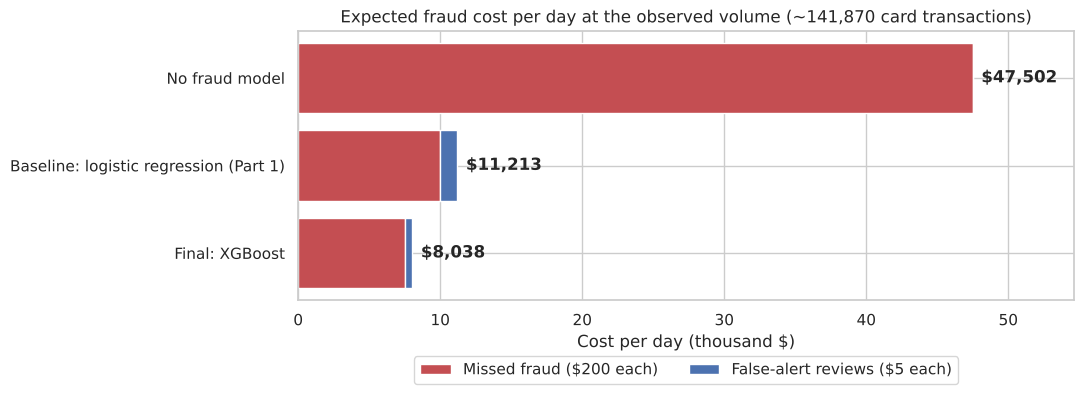

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.2))
plot_business = business.iloc[::-1] / 1000
ax.barh(plot_business.index, plot_business['missed-fraud cost per day $'], color='#C44E52',
        label='Missed fraud ($200 each)')
ax.barh(plot_business.index, plot_business['review cost per day $'],
        left=plot_business['missed-fraud cost per day $'], color='#4C72B0', label='False-alert reviews ($5 each)')
for i, total in enumerate(plot_business['total cost per day $']):
    ax.text(total + 0.6, i, f'${total * 1000:,.0f}', va='center', fontweight='bold')
ax.set_title(f'Expected fraud cost per day at the observed volume (~{daily_volume:,.0f} card transactions)')
ax.set_xlabel('Cost per day (thousand $)')
ax.set_xlim(0, plot_business['total cost per day $'].max() * 1.15)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/business_cost_per_day.png', bbox_inches='tight')
plt.show()

**What this means for the bank** (at this dataset's volume of about 141,900 transactions a day)
- **With no fraud model**, the bank would lose about **\$47,500 a day** to fraud.
- The **Part 1 baseline** cuts that to about **\$11,200 a day** and sends about 430 alerts a day to analysts.
- The **final XGBoost model** cuts it to about **\$8,000 a day**. That is roughly **\$3,200 a day less than the baseline**, with about **120 fewer alerts a day for analysts to review (308 vs 430)**.
- Missed fraud is still most of the remaining cost (\$7,500 of the \$8,000). One extra fraud caught is worth 40 false alerts, so future gains will come from catching the remaining ~16% of fraud, not from shrinking the review queue.

## 11. Conclusions, recommendations and next steps

### Findings
1. **Best model:** XGBoost (max depth 5, learning rate 0.1, `scale_pos_weight` = 10) is the best of six tuned models. Its CV PR-AUC is 0.853, and its test PR-AUC is 0.820 against 0.695 for the baseline.
2. **Business result:** at its cost-optimal threshold it catches 84% of fraud, and 65% of its alerts are real fraud. It cuts the test-set cost from \$4,485 (baseline) to \$3,215, a 28% saving (95% CI ≈ \$490 to \$2,290), and by 83% against having no model (\$19,000).
3. **Class imbalance:** the simple options (no resampling, or class weights) work as well as SMOTE, and random undersampling hurts. The decision threshold matters more than the resampling technique.
4. **Threshold:** the cost-optimal cut-off is far below 0.5 and must be tuned for each model and each cost assumption. Tuning it alone cut XGBoost's test cost from \$4,610 to \$3,215.
5. **Drivers:** V14 and V4 drive most predictions, which matches the EDA in Part 1.
6. **Caveat:** in an out-of-time test the ranking advantage held, but the threshold set on earlier data was slightly too conservative, so the two models' costs were similar.

### Recommendations
- **Pilot XGBoost in shadow mode first.** It scores live transactions alongside the current process without acting on them, and the outcomes are compared for a few weeks before switching over.
- **Set the alert threshold from business costs, not from 0.5.** Use the bank's own fraud-loss and review-cost estimates, and re-optimise whenever they change.
- **Monitor and recalibrate** the alert rate and threshold weekly to catch drift in fraud patterns. Retrain when PR-AUC on recently confirmed cases falls.
- **Plan analyst capacity** for about 300 alerts per day at a volume of about 142,000 transactions.

### Next steps
- Validate on a longer and more recent transaction history. This dataset covers only two days in 2013.
- Add behavioural features that this anonymised dataset lacks: customer spending velocity, merchant risk, device and location.
- Explain individual alerts (for example with SHAP values) so analysts can see why each transaction was flagged.
- Calibrate the probabilities, and move to a cost model that scales with transaction amount (a \$5,000 fraud costs more than a \$5 one).
- Package the model as a monitored API with automated retraining and a model card, following the MLOps practices in Mini-Lesson 24.1.

In [23]:
# Headline numbers quoted in the README
f, b = test_results.loc[final_name], test_results.loc[BASELINE]
print(f"Final model: {final_name} ({format_params(searches[final_name].best_params_)})")
print(f"Test PR-AUC {f['PR_AUC']:.3f} vs baseline {b['PR_AUC']:.3f} | threshold {thresholds[final_name]:.3f}")
print(f"Recall {f['recall']:.1%} | precision {f['precision']:.1%} | cost ${f['cost_$']:,.0f} "
      f"vs baseline ${b['cost_$']:,.0f} (saving ${b['cost_$'] - f['cost_$']:,.0f})")
print(f'Notebook runtime: {(time.time() - notebook_start) / 60:.1f} minutes')

Final model: XGBoost (learning_rate=0.1, max_depth=5, scale_pos_weight=10)
Test PR-AUC 0.820 vs baseline 0.695 | threshold 0.009
Recall 84.2% | precision 65.0% | cost $3,215 vs baseline $4,485 (saving $1,270)
Notebook runtime: 16.1 minutes
